In [1]:
#import necessary libraries and load the dataset
import pandas as pd

iris_df = pd.read_csv("../data/iris.csv")

print("Dataset shape:", iris_df.shape)
print("\nColumns:")
print(iris_df.columns.tolist())

iris_df.head()

Dataset shape: (150, 5)

Columns:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [2]:
#inspect the dataset
iris_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [3]:
#check for missing values and duplicates
print("Missing values:")
print(iris_df.isnull().sum())

print("\nDuplicate rows:")
print(iris_df.duplicated().sum())

Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Duplicate rows:
3


In [4]:
#drop duplicates
iris_df = iris_df.drop_duplicates()
print("Duplicate rows after dropping:")
print(iris_df.duplicated().sum())

Duplicate rows after dropping:
0


In [5]:
#check the distribution of the target variable
print(iris_df["species"].value_counts())

species
versicolor    50
virginica     49
setosa        48
Name: count, dtype: int64


In [6]:
print("Dataset shape after removing duplicates:", iris_df.shape)

Dataset shape after removing duplicates: (147, 5)


In [7]:
#split the dataset into features and target variable
X = iris_df.drop(columns=["species"])
y = iris_df["species"]

In [8]:
#split dataset into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (117, 4)
Testing set: (30, 4)


In [9]:
#Scale the features using StandardScaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [11]:
#train the logistic regression model
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=200,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",200
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbf

In [12]:
y_pred = logistic_model.predict(X_test_scaled)

print("Predictions:")
print(y_pred)

Predictions:
['versicolor' 'versicolor' 'virginica' 'setosa' 'virginica' 'virginica'
 'versicolor' 'setosa' 'virginica' 'virginica' 'setosa' 'setosa' 'setosa'
 'versicolor' 'virginica' 'setosa' 'versicolor' 'setosa' 'virginica'
 'setosa' 'versicolor' 'versicolor' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'virginica' 'virginica' 'versicolor']


In [13]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted"
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted"
)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

Accuracy: 0.9333
Precision: 0.9333
Recall: 0.9333


In [14]:
#get the predicted probabilities for each class
y_prob = logistic_model.predict_proba(X_test_scaled)

In [17]:
#convert the target variable to binary format for ROC curve
from sklearn.preprocessing import label_binarize

y_test_binary = label_binarize(
    y_test,
    classes=logistic_model.classes_
)

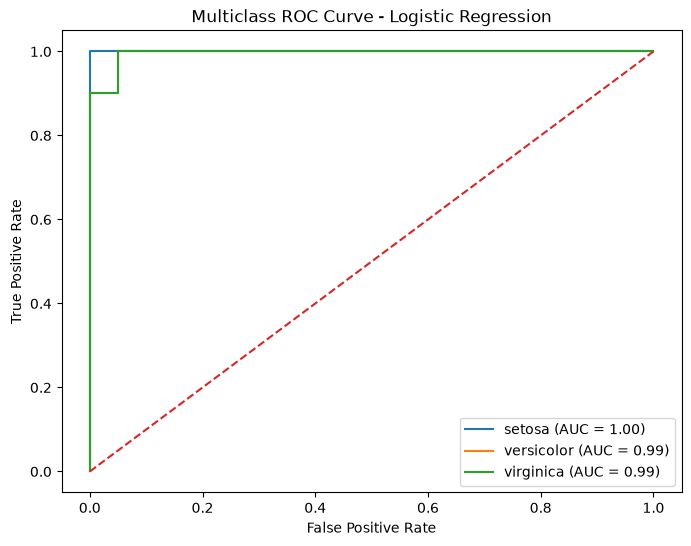

In [19]:
#compute the ROC curve and AUC for each class
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for i, species in enumerate(logistic_model.classes_):
    fpr, tpr, _ = roc_curve(
        y_test_binary[:, i],
        y_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{species} (AUC = {roc_auc:.2f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curve - Logistic Regression")
plt.legend()

plt.show()

In [20]:
#Deploy random forest classifier model
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train_scaled, y_train)

y_pred_rf = rf_model.predict(X_test_scaled)

In [21]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(
    y_test,
    y_pred_rf,
    average="weighted"
)
recall_rf = recall_score(
    y_test,
    y_pred_rf,
    average="weighted"
)

print(f"Random Forest Accuracy: {accuracy_rf:.4f}")
print(f"Random Forest Precision: {precision_rf:.4f}")
print(f"Random Forest Recall: {recall_rf:.4f}")

Random Forest Accuracy: 0.9667
Random Forest Precision: 0.9697
Random Forest Recall: 0.9667


In [22]:
#deploy support vector machine model
from sklearn.svm import SVC

svm_model = SVC(
    probability=True,
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)

C:\Users\franc\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [23]:
accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(
    y_test,
    y_pred_svm,
    average="weighted"
)
recall_svm = recall_score(
    y_test,
    y_pred_svm,
    average="weighted"
)

print(f"SVM Accuracy: {accuracy_svm:.4f}")
print(f"SVM Precision: {precision_svm:.4f}")
print(f"SVM Recall: {recall_svm:.4f}")

SVM Accuracy: 0.9667
SVM Precision: 0.9697
SVM Recall: 0.9667


In [ ]:
#compare the performance of the three models
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "SVM"
    ],
    "Accuracy": [
        accuracy,
        accuracy_rf,
        accuracy_svm
    ],
    "Precision": [
        precision,
        precision_rf,
        precision_svm
    ],
    "Recall": [
        recall,
        recall_rf,
        recall_svm
    ]
})

comparison

,Model,Accuracy,Precision,Recall
0,Logistic Regression,0.933333,0.933333,0.933333
1,Random Forest,0.966667,0.969697,0.966667
2,SVM,0.966667,0.969697,0.966667


## Key Findings

- The Iris dataset contained 150 observations and four numerical features used to predict flower species.
- Three duplicate observations were identified and removed, resulting in 147 observations for modelling.
- The three classes remained approximately balanced after removing duplicates.
- Logistic Regression achieved an accuracy, precision and recall of 93.33%.
- Random Forest and SVM both achieved 96.67% accuracy, 96.97% precision and 96.67% recall, outperforming Logistic Regression on the test set.
- The multiclass ROC analysis for Logistic Regression produced AUC scores of 1.00 for Setosa, 0.99 for Versicolor and 0.99 for Virginica, indicating excellent class discrimination.
- Random Forest and SVM produced identical test-set performance, making them joint best-performing models in this experiment.

## Business Implications

Although the Iris dataset is a benchmark dataset rather than a direct business dataset, the classification workflow demonstrates how supervised learning can support automated categorical decision-making.

The results show that machine learning models can classify observations into distinct categories with high accuracy when meaningful numerical features are available. In a real-world setting, a similar workflow could be applied to areas such as automated quality classification, product categorisation, or biological identification.

The comparison also demonstrates the importance of evaluating multiple models rather than assuming that the first model selected will provide the best performance. In this experiment, Random Forest and SVM both outperformed Logistic Regression.

## Limitations

- The Iris dataset is relatively small, containing only 147 observations after duplicate removal, so the results may not generalise to larger or more complex datasets.
- The dataset contains only four predictive features, which makes the classification problem considerably simpler than many real-world applications.
- The evaluation is based on a single train-test split, meaning performance may vary with a different split.
- Random Forest and SVM achieved the same test-set metrics, so the available evaluation results do not provide a clear basis for selecting one over the other.
- The ROC analysis was performed for Logistic Regression using a one-vs-rest approach for the three classes.
- The dataset is a benchmark dataset and therefore does not directly represent a production business environment.

## Conclusion

The classification task successfully demonstrated the use of Logistic Regression to predict Iris flower species. The Logistic Regression model achieved 93.33% accuracy, while Random Forest and SVM both achieved 96.67% accuracy.

The ROC analysis further demonstrated strong class discrimination, with AUC scores of 1.00 for Setosa and 0.99 for both Versicolor and Virginica. The comparison shows that evaluating multiple classification algorithms can improve model selection, as both Random Forest and SVM outperformed the Logistic Regression baseline.

Overall, the task demonstrated the complete classification workflow, from data preprocessing and feature scaling through model training, evaluation, ROC analysis and comparison of alternative algorithms.